# B16 — Exercice de code : GDA et Naive Bayes *from scratch*

**Bloc B16 — Generative learning algorithms** · notes CS229 ch. 4 (§4.1 et §4.2) · étape 5 du carnet (≈ 2 h)

Objectif : implémenter à la main les deux modèles génératifs du cours, puis vérifier qu'on retrouve exactement ce que fait scikit-learn.

| Partie | Modèle | Ce qu'on implémente |
|---|---|---|
| **A** | Gaussian Discriminant Analysis | les 4 estimateurs du maximum de vraisemblance **en forme fermée**, la règle de décision, la frontière linéaire |
| **B** | Naive Bayes, **multinomial event model** | vocabulaire, comptes, estimateurs avec **lissage de Laplace**, prédiction |

### Notation (convention CS229, celle du carnet)

- $n$ = nombre d'exemples, $d$ = nombre de features
- $x^{(i)} \in \mathbb{R}^{d}$, $y^{(i)} \in \{0, 1\}$
- Rappel : HOML utilise $m$ exemples et $n$ features ; **la vidéo du cours 5 écrit $\mathbb{R}^{n}$ au chapitre 5 puis $\mathbb{R}^{d}$ au chapitre 6 pour la même chose.** Ici c'est toujours $d$.

### Mode d'emploi

- Les cellules marquées **`# TODO`** sont à écrire par toi. Les autres sont fournies : lis-les, exécute-les.
- Chaque TODO est suivi d'un **checkpoint** : une cellule d'`assert` avec les valeurs attendues. Si elle passe sans rien afficher d'erreur, c'est bon.
- Les graines aléatoires sont fixées : **tu dois tomber exactement sur les mêmes nombres**.
- Les questions 🧠 sont à remplir dans les cellules markdown prévues.

> Travaille dans l'ordre : chaque étape réutilise la précédente.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["figure.dpi"] = 110
print("numpy", np.__version__)

numpy 2.3.5


---
# Partie A — Gaussian Discriminant Analysis

## A.0 — Le contexte et le modèle

On surveille des moteurs avec **deux mesures** :

| Feature | Unité | Signification |
|---|---|---|
| $x_{1}$ | mm/s | niveau vibratoire RMS |
| $x_{2}$ | °C | marge de température de gaz d'échappement (EGT margin) |

Deux classes : $y = 0$ moteur sain, $y = 1$ moteur à surveiller.

**Le modèle GDA** suppose que les données ont été fabriquées comme ceci :

$$y \sim \text{Bernoulli}(\phi)$$
$$x \mid y = 0 \;\sim\; \mathcal{N}(\mu_{0}, \Sigma) \qquad x \mid y = 1 \;\sim\; \mathcal{N}(\mu_{1}, \Sigma)$$

avec, pour $x \in \mathbb{R}^{d}$ :

$$p(x; \mu, \Sigma) = \frac{1}{(2\pi)^{d/2}\,\lvert\Sigma\rvert^{1/2}}\exp\left(-\frac{1}{2}(x - \mu)^{\top}\Sigma^{-1}(x - \mu)\right)$$

🔑 **L'hypothèse centrale : les deux classes partagent la même $\Sigma$.** Les deux nuages ont exactement la même forme et la même orientation, ils sont seulement translatés l'un par rapport à l'autre.

Ici on triche : on **génère** les données avec ce modèle, donc l'hypothèse est vraie par construction. C'est volontaire — on veut d'abord vérifier que l'estimation marche. On cassera l'hypothèse au bonus A.9.

In [2]:
# ---- Fourni : le vrai modèle génératif (les paramètres que GDA devra retrouver) ----
MU0_VRAI = np.array([2.0, 42.0])        # moteur sain
MU1_VRAI = np.array([3.6, 33.0])        # moteur à surveiller
SIGMA_VRAI = np.array([[0.36, -1.20],   # covariance PARTAGÉE
                       [-1.20, 25.00]])
PHI_VRAI = 0.35                         # proportion de la classe 1

def generer(n, seed):
    '''Tire n exemples du modèle GDA ci-dessus.'''
    rng = np.random.default_rng(seed)
    y = (rng.random(n) < PHI_VRAI).astype(int)
    X = np.empty((n, 2))
    for k, mu in enumerate((MU0_VRAI, MU1_VRAI)):
        masque = (y == k)
        X[masque] = rng.multivariate_normal(mu, SIGMA_VRAI, size=masque.sum())
    return X, y

X, y = generer(300, 42)          # training set
Xte, yte = generer(2000, 43)     # test set (grand, pour mesurer proprement)

print("X", X.shape, "| y", y.shape, "| exemples de classe 1 :", y.sum())
print("corrélation vraie entre les deux features :",
      round(SIGMA_VRAI[0, 1] / np.sqrt(SIGMA_VRAI[0, 0] * SIGMA_VRAI[1, 1]), 3))

X (300, 2) | y (300,) | exemples de classe 1 : 111
corrélation vraie entre les deux features : -0.4


## A.1 — Étape 1 : les quatre estimateurs du maximum de vraisemblance

C'est le cœur du cours : **pas de descente de gradient**, on annule les dérivées et on résout.

$$\phi = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left\{y^{(i)} = 1\right\}$$

$$\mu_{k} = \frac{\sum_{i=1}^{n} \mathbb{1}\left\{y^{(i)} = k\right\}\, x^{(i)}}{\sum_{i=1}^{n} \mathbb{1}\left\{y^{(i)} = k\right\}}$$

$$\Sigma = \frac{1}{n}\sum_{i=1}^{n} \left(x^{(i)} - \mu_{y^{(i)}}\right)\left(x^{(i)} - \mu_{y^{(i)}}\right)^{\top}$$

🧒 **En clair** : $\phi$ c'est « quelle fraction de la classe 1 ? » → on compte. $\mu_{k}$ c'est « où est le centre de chaque nuage ? » → on fait la moyenne. $\Sigma$ c'est « quelle forme ont les nuages ? » → pour **chaque** point on soustrait **la moyenne de sa propre classe**, puis on met tout en commun (*pooling*) : c'est ça qui rend la covariance partagée.

**Attention à trois pièges :**
1. Le $\frac{1}{n}$ de $\Sigma$ est bien $n$, **pas** $n - 2$. C'est l'estimateur du maximum de vraisemblance, biaisé mais c'est celui du cours.
2. $\Sigma$ doit sortir en $(d, d)$, donc produit **extérieur** $vv^{\top}$, pas produit scalaire.
3. Pour la somme, évite la boucle : construis la matrice $C$ des écarts centrés ligne par ligne, puis $\Sigma = \frac{1}{n} C^{\top}C$.

In [26]:
# Espace Notes
print(y.shape, X.shape)
n, d = X.shape
masque = (y==1)
print(len(X[y==1]))
len(y[masque])
print(len(y[y==0]))

(300,) (300, 2)
111
189


In [31]:
def ajuster_gda(X, y):
    '''Estimateurs du maximum de vraisemblance de GDA.
    Retourne (phi, mu0, mu1, Sigma) avec mu0, mu1 de forme (d,) et Sigma de forme (d, d).
    '''
    n, d = X.shape
    # TODO : phi
    phi = 1/n * sum(y[y==1])
    # TODO : mu0 et mu1
    mu0 = sum(X[y==0])/len(y[y==0])
    mu1 = sum(X[y==1])/sum(y[y==1])
    # TODO : Sigma (indice : np.where(y[:, None] == 1, mu1, mu0) donne la bonne moyenne pour chaque ligne)
    C = X - np.where(y[:, None] == 1, mu1, mu0)
    Sigma = 1/n * C.T @ C
    return phi, mu0, mu1, Sigma


phi, mu0, mu1, Sigma = ajuster_gda(X, y)
print("phi   =", phi)
print("mu0   =", mu0, "   (vrai :", MU0_VRAI, ")")
print("mu1   =", mu1, "   (vrai :", MU1_VRAI, ")")
print("Sigma =\n", Sigma, "\n(vrai :\n", SIGMA_VRAI, ")")

phi   = 0.37000000000000005
mu0   = [ 1.9843 41.8754]    (vrai : [ 2. 42.] )
mu1   = [ 3.5766 32.8234]    (vrai : [ 3.6 33. ] )
Sigma =
 [[ 0.3129 -0.7801]
 [-0.7801 26.5132]] 
(vrai :
 [[ 0.36 -1.2 ]
 [-1.2  25.  ]] )


In [32]:
# ---- CHECKPOINT 1 ----
assert np.isclose(phi, 0.37), f"phi attendu 0.37, obtenu {phi}"
assert np.allclose(mu0, [1.9843, 41.8754], atol=1e-4), mu0
assert np.allclose(mu1, [3.5766, 32.8234], atol=1e-4), mu1
assert np.allclose(Sigma, [[0.3129, -0.7801], [-0.7801, 26.5132]], atol=1e-4), Sigma
assert np.allclose(Sigma, Sigma.T), "Sigma doit être symétrique"
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "Sigma doit être définie positive"
print("✅ Checkpoint 1 — estimateurs OK")

✅ Checkpoint 1 — estimateurs OK


## A.2 — Étape 2 : la log-densité gaussienne multivariée

On travaille **toujours en log** : les densités en grande dimension valent $10^{-300}$, le produit brut tombe à zéro en virgule flottante.

$$\log p(x; \mu, \Sigma) = -\frac{1}{2}\Big( d\log(2\pi) \;+\; \log\lvert\Sigma\rvert \;+\; \underbrace{(x - \mu)^{\top}\Sigma^{-1}(x - \mu)}_{\text{distance de Mahalanobis au carré}} \Big)$$

**Indices :**
- `np.linalg.slogdet(Sigma)` renvoie `(signe, log|det|)` — plus stable que `np.log(np.linalg.det(...))`.
- Pour la forme quadratique sur toutes les lignes d'un coup : `np.einsum("ij,jk,ik->i", diff, Sigma_inv, diff)`.
- La fonction doit accepter un tableau `X` de forme $(n, d)$ et renvoyer un vecteur de forme $(n,)$.

In [77]:
def log_densite_normale(X, mu, Sigma):
    '''log p(x ; mu, Sigma) pour chaque ligne de X. Renvoie un vecteur (n,).'''
    n, d = X.shape

    # Preparations intermédiaires
    signe, log_det = np.linalg.slogdet(Sigma)
    assert signe == +1, "Matrice non définie positive"
    
    Sigma_inv = np.linalg.inv(Sigma)
    #mahalanobis = (X - mu) @ Sigma_inv @ (X - mu).T
    
    vecteur_taille_nxd = (X - mu) @ Sigma_inv
    #print(vecteur_taille_nxd.shape)

    vecteur_produit_termeaterme = vecteur_taille_nxd * (X - mu)
    mahalanobis = np.sum(vecteur_produit_termeaterme, axis=1)
    #print(mahalanobis.shape)
    assert mahalanobis.shape == (n,), f"forme {mahalanobis.shape}, attendu ({n},)"
    
    
    # Calcul log densite normale
    log_densite = -1/2 * (d * np.log(2*np.pi) + log_det + mahalanobis)
    
    
    return log_densite

print(log_densite_normale(X[:3], mu0, Sigma))

[-2.8917 -2.9098 -7.9398]


In [61]:
# ---- CHECKPOINT 2 ----
v = log_densite_normale(X, mu0, Sigma)
assert v.shape == (300,), f"forme attendue (300,), obtenue {v.shape}"
assert np.isclose(v[0], -2.891702, atol=1e-5), v[0]
# une densité intègre à 1 : vérification par échantillonnage de Monte-Carlo
rng_test = np.random.default_rng(0)
boite = rng_test.uniform([0, 20], [6, 65], size=(400000, 2))
aire = 6 * 45
integrale = np.exp(log_densite_normale(boite, mu0, Sigma)).mean() * aire
assert abs(integrale - 1.0) < 0.02, f"la densité n'intègre pas à 1 : {integrale}"
print(f"✅ Checkpoint 2 — log-densité OK (intégrale numérique = {integrale:.4f})")

(300, 2)
(300,)
(400000, 2)
(400000,)
✅ Checkpoint 2 — log-densité OK (intégrale numérique = 1.0013)


## A.3 — Étape 3 : prédire avec la règle de Bayes

$$\hat{y} = \arg\max_{y} \; p(y \mid x) = \arg\max_{y} \; \frac{p(x \mid y)\,p(y)}{p(x)} = \arg\max_{y} \; p(x \mid y)\,p(y)$$

⚠️ **Le piège de la vidéo (46:14).** C'est $p(x)$ qui disparaît, parce qu'il vaut la même chose pour les deux classes et ne change donc pas l'argmax. **$p(y)$ reste** : c'est le class prior, et c'est tout l'intérêt du modèle génératif. Sur la slide du cours, le conférencier dit lui-même à voix haute que ce qui est écrit est faux.

En log, le score de la classe $k$ est donc :

$$s_{k}(x) = \log p(x \mid y = k) + \log p(y = k), \qquad \log p(y=1) = \log \phi, \quad \log p(y=0) = \log(1 - \phi)$$

In [66]:
X[3]

array([ 2.1544, 40.8205])

In [78]:
def predire_gda(X, phi, mu0, mu1, Sigma):
    '''Renvoie les classes prédites (0 ou 1) pour chaque ligne de X.'''
    
    # TODO : score de chaque classe = log densité + log prior, puis comparaison
    sk_0 = log_densite_normale(X, mu0, Sigma) + np.log(1-phi)
    sk_1 = log_densite_normale(X, mu1, Sigma) + np.log(phi)
    pred_sk_x = (sk_0 < sk_1).astype(int)
    return pred_sk_x


acc_train = (predire_gda(X, phi, mu0, mu1, Sigma) == y).mean()
acc_test = (predire_gda(Xte, phi, mu0, mu1, Sigma) == yte).mean()
print(f"accuracy train : {acc_train:.4f}")
print(f"accuracy test  : {acc_test:.4f}")

accuracy train : 0.9600
accuracy test  : 0.9165


In [70]:
# ---- CHECKPOINT 3 ----
assert np.isclose(acc_train, 0.96, atol=1e-6), acc_train
assert np.isclose(acc_test, 0.9165, atol=1e-6), acc_test
print("✅ Checkpoint 3 — prédiction OK")

✅ Checkpoint 3 — prédiction OK


## A.4 — Étape 4 : la frontière de décision est une **droite**

C'est le résultat principal du cours. On développe la forme quadratique :

$$(x - \mu_{k})^{\top}\Sigma^{-1}(x - \mu_{k}) = \underbrace{x^{\top}\Sigma^{-1}x}_{\text{quadratique}} - 2\,\mu_{k}^{\top}\Sigma^{-1}x + \underbrace{\mu_{k}^{\top}\Sigma^{-1}\mu_{k}}_{\text{constante}}$$

Le terme quadratique $x^{\top}\Sigma^{-1}x$ est **le même pour les deux classes** (c'est la même $\Sigma$) : en égalant les deux scores, **il s'annule**. Il ne reste que du linéaire :

$$\log\frac{p(y = 1 \mid x)}{p(y = 0 \mid x)} = w^{\top}x + b$$

$$\boxed{\;w = \Sigma^{-1}(\mu_{1} - \mu_{0}), \qquad b = -\frac{1}{2}\left(\mu_{1}^{\top}\Sigma^{-1}\mu_{1} - \mu_{0}^{\top}\Sigma^{-1}\mu_{0}\right) + \log\frac{\phi}{1 - \phi}\;}$$

Remarque le $\log\frac{\phi}{1-\phi}$ (le **log odds** du prior) : il **déplace** la frontière sans l'incliner.

**À vérifier :** la règle « argmax des densités » de l'étape 3 et la règle « $w^{\top}x + b > 0$ » doivent donner **exactement les mêmes prédictions**, sur tous les points.

In [98]:
def frontiere_gda(phi, mu0, mu1, Sigma):
    '''Renvoie (w, b) de l'hyperplan séparateur.'''
    # TODO
    Sigma_inv = np.linalg.inv(Sigma)
    w = Sigma_inv @ (mu1 - mu0)
    b = -1/2 * (mu1 @ Sigma_inv @ mu1.T - mu0 @ Sigma_inv @ mu0.T) + np.log(phi/(1-phi)) 
    return w, b

w, b = frontiere_gda(phi, mu0, mu1, Sigma)
print(b.shape)
print("w =", w)
print("b =", round(float(b), 4))

()
w = [ 4.5725 -0.2069]
b = -5.5197


In [99]:
# ---- CHECKPOINT 4 ----
assert np.allclose(w, [4.5725, -0.2069], atol=1e-4), w
assert np.isclose(b, -5.5197, atol=1e-4), b
desaccords = ((Xte @ w + b > 0).astype(int) != predire_gda(Xte, phi, mu0, mu1, Sigma)).sum()
assert desaccords == 0, f"{desaccords} désaccords entre les deux règles — elles doivent être identiques"
print("✅ Checkpoint 4 — frontière linéaire OK, 0 désaccord sur 2000 points de test")

✅ Checkpoint 4 — frontière linéaire OK, 0 désaccord sur 2000 points de test


## A.5 — Visualisation (fourni)

Les deux ellipses sont les contours à $1\sigma$ et $2\sigma$ : **même forme, même orientation**, seul le centre change. La droite est la frontière de décision.

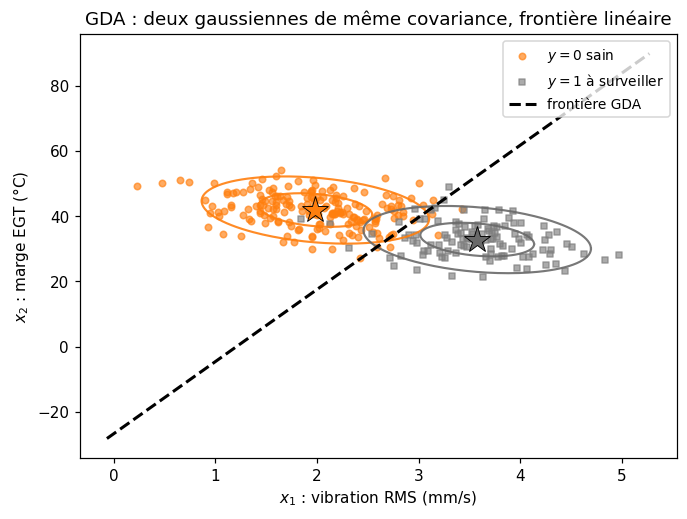

In [100]:
def ellipse_niveau(mu, Sigma, k_sigma=1.0, npts=200):
    '''Points de l'ellipse de niveau à k_sigma écarts-types (contour de la gaussienne).'''
    t = np.linspace(0, 2 * np.pi, npts)
    cercle = np.vstack([np.cos(t), np.sin(t)])
    L = np.linalg.cholesky(Sigma)
    return mu[:, None] + k_sigma * (L @ cercle)

fig, ax = plt.subplots()
ax.scatter(*X[y == 0].T, s=18, c="tab:orange", alpha=.65, label="$y=0$ sain")
ax.scatter(*X[y == 1].T, s=18, c="tab:gray", marker="s", alpha=.65, label="$y=1$ à surveiller")
for mu, col in ((mu0, "tab:orange"), (mu1, "dimgray")):
    for k in (1, 2):
        ax.plot(*ellipse_niveau(mu, Sigma, k), color=col, lw=1.4, alpha=.9)
    ax.plot(*mu, marker="*", ms=18, color=col, mec="k", mew=.6)

xs = np.linspace(X[:, 0].min() - .3, X[:, 0].max() + .3, 2)
ax.plot(xs, -(w[0] * xs + b) / w[1], "k--", lw=2, label="frontière GDA")
ax.set_xlabel("$x_1$ : vibration RMS (mm/s)")
ax.set_ylabel("$x_2$ : marge EGT (°C)")
ax.set_title("GDA : deux gaussiennes de même covariance, frontière linéaire")
ax.legend(loc="upper right", fontsize=9)
plt.show()

## A.6 — Comparaison avec scikit-learn (fourni)

Deux comparaisons très différentes :

1. **`LinearDiscriminantAnalysis`** = GDA. Ça doit tomber **exactement** sur tes nombres (même estimateur, même normalisation en $\frac{1}{n}$).
2. **`LogisticRegression`** = la version discriminative. Ça ne doit **pas** donner les mêmes coefficients — mais une frontière très proche.

In [101]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression

lda = LinearDiscriminantAnalysis(store_covariance=True).fit(X, y)
logreg = LogisticRegression(C=np.inf, max_iter=5000).fit(X, y)   # C=inf : aucune régularisation

print("--- LDA de scikit-learn vs notre GDA ---")
print("coef      :", lda.coef_[0], " | notre w :", w)
print("intercept :", round(float(lda.intercept_[0]), 4), " | notre b :", round(float(b), 4))
print("écart max sur la covariance :", np.abs(lda.covariance_ - Sigma).max())
print("désaccords de prédiction sur le test :",
      int((lda.predict(Xte) != predire_gda(Xte, phi, mu0, mu1, Sigma)).sum()))

print("\n--- Logistic regression (discriminative) ---")
print("coef      :", logreg.coef_[0])
print("intercept :", round(float(logreg.intercept_[0]), 4))
cos = float(w @ logreg.coef_[0] / (np.linalg.norm(w) * np.linalg.norm(logreg.coef_[0])))
print(f"cosinus entre les deux vecteurs normaux : {cos:.6f}")
print(f"accuracy test — GDA {acc_test:.4f}  |  logistic regression {logreg.score(Xte, yte):.4f}")

--- LDA de scikit-learn vs notre GDA ---
coef      : [ 4.542  -0.2055]  | notre w : [ 4.5725 -0.2069]
intercept : -5.4864  | notre b : -5.5197
écart max sur la covariance : 7.105427357601002e-15
désaccords de prédiction sur le test : 0

--- Logistic regression (discriminative) ---
coef      : [ 5.5046 -0.2304]
intercept : -7.404
cosinus entre les deux vecteurs normaux : 0.999994
accuracy test — GDA 0.9165  |  logistic regression 0.9160


In [103]:
# ---- CHECKPOINT 5 (robuste à la version de scikit-learn) ----
import sklearn
n, K = len(y), 2
cos = float(lda.coef_[0] @ w / (np.linalg.norm(lda.coef_[0]) * np.linalg.norm(w)))

assert np.allclose(lda.covariance_, Sigma, atol=1e-10), "LDA doit retrouver notre Sigma"
assert abs(cos - 1) < 1e-10, "la direction de la frontiere doit etre identique"
assert (np.allclose(lda.coef_[0], w, atol=1e-8)
        or np.allclose(lda.coef_[0], w * (n - K) / n, atol=1e-8)), \
    "coef_ doit valoir w (normalisation 1/n) ou w*(n-K)/n selon la version"
assert (lda.predict(Xte) != predire_gda(Xte, phi, mu0, mu1, Sigma)).sum() == 0, \
    "LDA et notre GDA doivent predire la meme chose"

print(f"scikit-learn {sklearn.__version__} | rapport coef_/w = {(lda.coef_[0]/w)[0]:.7f}")
print("✅ Checkpoint 5 — notre GDA est identique au LDA de scikit-learn")

scikit-learn 1.7.2 | rapport coef_/w = 0.9933333
✅ Checkpoint 5 — notre GDA est identique au LDA de scikit-learn


### 🧠 Question Q1

Les coefficients de la logistic regression ($\approx[5.50,\,-0.23]$, intercept $-7.40$) sont **différents** de ceux de GDA ($\approx[4.57,\,-0.21]$, intercept $-5.52$), alors que le cosinus entre les deux vecteurs normaux vaut $0{,}999994$ et que les deux accuracies sont égales à $0{,}001$ près.

Explique **pourquoi les coefficients diffèrent alors que la frontière est quasiment la même**. Qu'est-ce que chacun des deux modèles cherche à maximiser ?

> *Ta réponse :*
>
>

### 🧠 Question Q2

Le cours démontre que **GDA $\Rightarrow$ le postérieur $p(y = 1 \mid x)$ a la forme sigmoïdale de la logistic regression**, mais que **la réciproque est fausse**.

Si GDA implique la forme logistique, pourquoi les deux méthodes ne trouvent-elles pas le même $(w, b)$ ?

> *Ta réponse :*
>
>

## A.7 — Expérience : GDA contre logistic regression à petit $n$ (fourni, ≈ 20 s)

L'argument classique : GDA fait **plus d'hypothèses**, donc il a **moins à apprendre** ; quand l'hypothèse est vraie, il devrait atteindre sa performance asymptotique **avec moins de données**.

Ici l'hypothèse gaussienne est vraie par construction : c'est le terrain le plus favorable possible pour GDA. On réentraîne les deux modèles sur des échantillons de taille croissante, 400 tirages par taille, et on évalue sur un gros test set fixe.

In [ ]:
Xgros, ygros = generer(4000, 999)
rng_exp = np.random.default_rng(7)
tailles = (8, 12, 16, 24, 32, 48, 64, 100, 200)
moy_gda, moy_log = [], []

for n in tailles:
    a_g, a_l = [], []
    for _ in range(400):
        Xs, ys = generer(n, int(rng_exp.integers(1e9)))
        if ys.sum() < 2 or (1 - ys).sum() < 2:      # il faut au moins 2 points par classe
            continue
        a_g.append((predire_gda(Xgros, *ajuster_gda(Xs, ys)) == ygros).mean())
        a_l.append(LogisticRegression(C=np.inf, max_iter=2000).fit(Xs, ys).score(Xgros, ygros))
    moy_gda.append(np.mean(a_g)); moy_log.append(np.mean(a_l))
    print(f"n = {n:4d}   GDA {np.mean(a_g):.4f}   logistic regression {np.mean(a_l):.4f}")

fig, ax = plt.subplots()
ax.plot(tailles, moy_gda, "o-", label="GDA")
ax.plot(tailles, moy_log, "s-", label="logistic regression")
ax.set_xscale("log"); ax.set_xlabel("taille du training set $n$ (échelle log)")
ax.set_ylabel("accuracy moyenne sur le test set")
ax.set_title("Qui apprend le plus vite quand les données sont rares ?")
ax.grid(alpha=.3); ax.legend()
plt.show()

### 🧠 Question Q3

Trois choses à expliquer dans cette courbe :

1. À partir de $n = 16$, GDA est **systématiquement devant**. Pourquoi ?
2. À $n = 8$, GDA repasse **légèrement derrière**. Qu'est-ce qui se dégrade en premier quand il ne reste que 8 points ? (compte le nombre de paramètres de $\Sigma$)
3. Les deux courbes **se rejoignent** quand $n$ grandit. Qu'est-ce que ça dit du compromis « hypothèses fortes / hypothèses faibles » ?

> *Ta réponse :*
>
>

## A.8 — Bonus : casser l'hypothèse de covariance partagée (QDA)

On génère maintenant des données où **les deux classes n'ont pas la même covariance**. Le terme $x^{\top}\Sigma^{-1}x$ ne s'annule plus : la frontière optimale devient **quadratique**. C'est la *Quadratic Discriminant Analysis*.

L'estimation change sur un seul point : au lieu de mettre toutes les données en commun, on estime **une covariance par classe**.

In [ ]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

SIGMA1_Q = np.array([[1.44, 2.40], [2.40, 25.00]])   # covariance DIFFÉRENTE pour la classe 1

def generer_q(n, seed):
    rng = np.random.default_rng(seed)
    y = (rng.random(n) < 0.5).astype(int)
    X = np.empty((n, 2))
    X[y == 0] = rng.multivariate_normal(MU0_VRAI, SIGMA_VRAI, size=(y == 0).sum())
    X[y == 1] = rng.multivariate_normal(MU0_VRAI + np.array([1.0, -2.0]), SIGMA1_Q, size=(y == 1).sum())
    return X, y

Xq, yq = generer_q(400, 11)
Xqte, yqte = generer_q(2000, 12)

acc_lin = (predire_gda(Xqte, *ajuster_gda(Xq, yq)) == yqte).mean()
acc_quad = QuadraticDiscriminantAnalysis().fit(Xq, yq).score(Xqte, yqte)
print(f"GDA (covariance partagée, frontière linéaire) : {acc_lin:.4f}")
print(f"QDA (une covariance par classe, frontière quadratique) : {acc_quad:.4f}")

# la frontière de QDA, en image
qda = QuadraticDiscriminantAnalysis().fit(Xq, yq)
g1, g2 = np.meshgrid(np.linspace(*np.percentile(Xq[:, 0], [0, 100]), 300),
                     np.linspace(*np.percentile(Xq[:, 1], [0, 100]), 300))
Z = qda.predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
fig, ax = plt.subplots()
ax.contourf(g1, g2, Z, levels=[-.5, .5, 1.5], colors=["#ffe9d6", "#e8e8e8"])
ax.scatter(*Xq[yq == 0].T, s=14, c="tab:orange", alpha=.7, label="$y=0$")
ax.scatter(*Xq[yq == 1].T, s=14, c="dimgray", marker="s", alpha=.7, label="$y=1$")
ax.set_title("QDA : covariances différentes $\\Rightarrow$ frontière quadratique")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend()
plt.show()

### 🧠 Question Q4

Dans ce jeu de données, QDA gagne environ 4 points d'accuracy sur GDA linéaire. Pourtant le cours commence par le modèle à covariance partagée.

Combien de paramètres libres contient une covariance symétrique en dimension $d$ ? Et pour $K$ classes en QDA ? À partir de quelle dimension $d$ ce choix devient-il coûteux, et que se passe-t-il si une classe contient moins de $d$ exemples ?

> *Ta réponse :*
>
>

---
# Partie B — Naive Bayes, *multinomial event model*

## B.0 — Pourquoi un autre modèle, et lequel

GDA travaille sur des features **continues**. Pour du texte, il faut autre chose.

⚠️ **Il existe deux modèles d'événements distincts** (notes §4.2.2) — c'est le test de maîtrise **B16-6**, et **la vidéo ne présente que le premier** :

| Modèle | Ce qu'est $x$ | Ce qu'on compte |
|---|---|---|
| **Multivariate Bernoulli event model** | un vecteur $x \in \{0,1\}^{\lvert V\rvert}$ : le mot est présent ou absent | la **présence** d'un mot, une fois par message |
| **Multinomial event model** ← *celui qu'on implémente* | une **suite** $x_{1}, \dots, x_{n_{i}}$ où $x_{j} \in \{1, \dots, \lvert V\rvert\}$ est l'identité du $j$-ème mot | le **nombre d'occurrences** : un mot répété 3 fois compte 3 fois |

Le message $i$ a sa propre longueur $n_{i}$.

### Le modèle

$$p(y) = \phi_{y}^{\,y}(1 - \phi_{y})^{1-y}, \qquad p\left(x_{1}, \dots, x_{n_{i}} \mid y\right) = \prod_{j=1}^{n_{i}} p\left(x_{j} \mid y\right)$$

L'**hypothèse Naive Bayes** : sachant la classe, les mots sont tirés **indépendamment** les uns des autres. À comparer à la règle des probabilités composées, qui elle est toujours vraie :

$$p\left(x_{1}, \dots, x_{n_i} \mid y\right) = \prod_{j=1}^{n_{i}} p\left(x_{j} \mid x_{1}, \dots, x_{j-1}, y\right)$$

**L'hypothèse NB consiste exactement à jeter tout le conditionnement sur les autres mots.** C'est faux — « ce n'est **pas** le pire » : *pas* et *pire* sont comptés séparément puis multipliés — et pourtant ça classe très bien.

### Le gain

| | Nombre de paramètres |
|---|---|
| Loi multinomiale complète sur $\{0,1\}^{\lvert V\rvert}$ | $2^{\lvert V\rvert} - 1$ |
| Naive Bayes | $2\lvert V\rvert + 1$ |

Exponentiel → linéaire.

### Les paramètres à estimer

$$\phi_{y} = p(y = 1), \qquad \phi_{k \mid y = 1} = p\left(x_{j} = k \mid y = 1\right), \qquad \phi_{k \mid y = 0} = p\left(x_{j} = k \mid y = 0\right)$$

🔑 Pour chaque classe, $\left(\phi_{k \mid y}\right)_{k=1..\lvert V\rvert}$ est **une loi de probabilité sur le vocabulaire** : elle somme à 1. C'est la différence avec le modèle de Bernoulli, où chaque mot a sa propre pièce indépendante.

In [ ]:
SPAM = [
    "Gagnez un iPhone gratuit cliquez ici maintenant",
    "Offre exceptionnelle credit immediat sans justificatif cliquez ici",
    "Vous avez gagne mille euros reclamez votre gain maintenant",
    "Cliquez ici pour recevoir votre cadeau gratuit immediat",
    "Derniere chance offre gratuite reservee a vous cliquez vite",
    "Votre colis vous attend confirmez votre adresse maintenant",
    "Felicitations vous etes le gagnant reclamez votre prix gratuit",
    "Credit sans frais reponse immediate cliquez sur le lien",
    "Offre limitee gratuit pendant vingt quatre heures cliquez",
    "Votre compte sera suspendu confirmez vos informations maintenant",
    "Rencontrez des celibataires gratuitement pres de chez vous",
    "Gagnez de l argent facilement depuis chez vous sans effort",
    "Promotion exceptionnelle montres de luxe prix casse cliquez",
    "Vous avez un remboursement en attente confirmez votre compte",
    "Investissez maintenant et doublez votre argent garanti",
    "Cliquez ici pour votre bilan de sante gratuit offert",
    "Offre speciale abonnement gratuit le premier mois cliquez",
    "Urgent votre carte a ete bloquee confirmez vos informations",
    "Reclamez vos mille euros de bons d achat gratuit maintenant",
    "Travaillez depuis chez vous et gagnez beaucoup d argent",
    "Votre numero a ete tire au sort vous avez gagne un voyage",
    "Medicaments pas chers livraison gratuite commandez maintenant",
    "Augmentez vos revenus rapidement methode garantie cliquez ici",
    "Offre gratuite valable aujourd hui seulement cliquez vite",
]

HAM = [
    "Reunion de suivi demain a quatorze heures en salle B douze",
    "Je t envoie le rapport de calcul vibratoire ce soir",
    "Peux tu relire le compte rendu de la revue de conception",
    "La campagne d essais est decalee a la semaine prochaine",
    "Merci pour les mesures je regarde les spectres cet apres midi",
    "Le client demande une note de synthese pour vendredi",
    "J ai mis a jour le modele dans le depot git tu peux tirer",
    "Reunion annulee ce matin nous la reportons a demain",
    "Peux tu me renvoyer le cahier des charges derniere version",
    "Les resultats de la soufflerie arrivent en fin de semaine",
    "Je serai en conge la semaine prochaine voici mes dossiers",
    "Le rapport est relu il reste deux corrections a faire",
    "Point telephonique a dix heures pour caler le planning",
    "Peux tu verifier les tolerances sur le plan de la piece",
    "La revue de projet est confirmee pour mardi prochain",
    "Je t ai partage le dossier sur le serveur tu as les droits",
    "Merci d avoir corrige le script le calcul tourne maintenant",
    "Le fournisseur confirme la livraison pour la fin du mois",
    "On se cale un point demain matin pour la note de calcul",
    "Les essais de vibration sont termines je prepare le rapport",
    "Peux tu valider le compte rendu avant que je l envoie",
    "Le planning de la campagne est mis a jour sur le serveur",
    "Je reprends les mesures demain avec le nouveau capteur",
    "Compte rendu de la reunion en piece jointe bonne lecture",
]

print(f"{len(SPAM)} spams, {len(HAM)} messages légitimes")
print("exemple de spam :", SPAM[0])
print("exemple de ham  :", HAM[0])

In [ ]:
# ---- Fourni : tokenisation et découpage train / test ----
MOTIF = r"[a-zA-ZÀ-ÖØ-öø-ÿ]{2,}"       # suites de lettres de longueur >= 2 (les élisions "l", "d", "j" sautent)

def tokeniser(texte):
    return re.findall(MOTIF, texte.lower())

docs = SPAM + HAM
labels = np.array([1] * len(SPAM) + [0] * len(HAM))     # 1 = spam

rng_split = np.random.default_rng(0)
idx_tr, idx_te = [], []
for k in (0, 1):                                        # découpage stratifié : 18 / 6 par classe
    idx = rng_split.permutation(np.where(labels == k)[0])
    idx_tr += list(idx[:18]); idx_te += list(idx[18:])
idx_tr, idx_te = np.array(sorted(idx_tr)), np.array(sorted(idx_te))

docs_tr = [docs[i] for i in idx_tr]; y_tr = labels[idx_tr]
docs_te = [docs[i] for i in idx_te]; y_te = labels[idx_te]

print(f"train : {len(docs_tr)} messages dont {y_tr.sum()} spams")
print(f"test  : {len(docs_te)} messages dont {y_te.sum()} spams")
print("tokenisation :", tokeniser(SPAM[0]))

## B.1 — Étape 5 : le vocabulaire

Construis `vocab`, la **liste triée** des mots distincts apparaissant dans les messages **d'entraînement**, et `index`, le dictionnaire `mot -> colonne`.

⚠️ **Uniquement les messages d'entraînement.** Construire le vocabulaire sur l'ensemble du corpus serait une fuite de données (*data leakage*) : le modèle verrait des mots du test set avant l'évaluation.

In [ ]:
# TODO : vocab (liste triée) et index (dict mot -> position)
vocab = ...
index = ...
V = len(vocab)

print("taille du vocabulaire V =", V)
print("5 premiers mots :", vocab[:5])

In [ ]:
# ---- CHECKPOINT 6 ----
assert V == 182, f"V attendu 182, obtenu {V}"
assert vocab[:5] == ["abonnement", "achat", "adresse", "ai", "annulee"], vocab[:5]
assert index[vocab[17]] == 17, "index doit donner la position dans vocab"
print("✅ Checkpoint 6 — vocabulaire OK")

## B.2 — Étape 6 : la matrice des comptes

`compter(docs, index)` renvoie une matrice d'entiers de forme $(\text{nb de messages}, \lvert V\rvert)$ où la case $(i, k)$ est **le nombre d'occurrences** du mot $k$ dans le message $i$.

C'est ici que se joue la différence entre les deux modèles d'événements : on met **le compte**, pas un 0/1.

⚠️ Un message de test peut contenir un mot absent du vocabulaire (*out of vocabulary*). Ignore-le simplement.

In [ ]:
def compter(docs, index):
    '''Matrice (nb_docs, V) du nombre d'occurrences de chaque mot du vocabulaire.'''
    C = np.zeros((len(docs), len(index)), dtype=int)
    # TODO
    return C


Ctr = compter(docs_tr, index)
Cte = compter(docs_te, index)
print("Ctr", Ctr.shape, "| total de mots dans le train :", Ctr.sum())
print("dont dans les spams :", Ctr[y_tr == 1].sum())

In [ ]:
# ---- CHECKPOINT 7 ----
assert Ctr.shape == (36, 182) and Cte.shape == (12, 182)
assert Ctr.sum() == 330, Ctr.sum()
assert Ctr[y_tr == 1].sum() == 152, Ctr[y_tr == 1].sum()
assert Ctr.max() >= 2, "un message au moins doit contenir un mot répété — sinon tu as fait du 0/1"
print("✅ Checkpoint 7 — comptes OK")

## B.3 — Étape 7 : estimation avec **lissage de Laplace**

Prior de classe :

$$\phi_{y} = \frac{1}{n}\sum_{i=1}^{n}\mathbb{1}\left\{y^{(i)} = 1\right\}$$

Probabilité du mot $k$ dans la classe $c$, **avec lissage** :

$$\phi_{k \mid y = c} \;=\; \frac{\left(\displaystyle\sum_{i\,:\,y^{(i)} = c} \text{compte}_{i,k}\right) + \alpha}{\left(\displaystyle\sum_{i\,:\,y^{(i)} = c} \sum_{k'=1}^{\lvert V\rvert} \text{compte}_{i,k'}\right) + \alpha\,\lvert V\rvert}$$

🧒 **En clair** : « parmi tous les mots des spams, quelle fraction est le mot $k$ ? », mais on fait **comme si on avait vu chaque mot du vocabulaire $\alpha$ fois de plus**. Le $\alpha\lvert V\rvert$ du dénominateur, c'est ce qu'il faut rajouter pour que la somme fasse toujours 1.

Pourquoi c'est vital : **un seul mot jamais vu dans une classe donnerait $\phi = 0$, donc un produit nul**, et un zéro écrase toutes les autres preuves, aussi écrasantes soient-elles. Le lissage de Laplace, c'est $\alpha = 1$.

**Renvoie directement les logs** : `log_prior` de forme $(2,)$ et `log_phi` de forme $(2, \lvert V\rvert)$, la ligne 0 pour les messages légitimes, la ligne 1 pour les spams.

In [ ]:
def ajuster_nb(C, y, alpha=1.0):
    '''Naive Bayes multinomial. Renvoie (log_prior, log_phi) de formes (2,) et (2, V).'''
    V = C.shape[1]
    log_prior = np.empty(2)
    log_phi = np.empty((2, V))
    for c in (0, 1):
        # TODO : log_prior[c] et log_phi[c]
        ...
    return log_prior, log_phi


log_prior, log_phi = ajuster_nb(Ctr, y_tr, alpha=1.0)
j = index["cliquez"]
print("log prior      :", log_prior)
print("log phi 'cliquez' | spam :", round(float(log_phi[1, j]), 6))
print("log phi 'cliquez' | ham  :", round(float(log_phi[0, j]), 6))
print("somme des probabilités de la classe spam :", np.exp(log_phi[1]).sum())

In [ ]:
# ---- CHECKPOINT 8 ----
assert np.allclose(log_prior, [-0.693147, -0.693147], atol=1e-5), log_prior
assert np.isclose(log_phi[1, index["cliquez"]], -3.731699, atol=1e-5), log_phi[1, index["cliquez"]]
assert np.isclose(log_phi[0, index["cliquez"]], -5.886104, atol=1e-5), log_phi[0, index["cliquez"]]
assert np.allclose(np.exp(log_phi).sum(axis=1), 1.0), "chaque ligne doit être une loi de probabilité sur le vocabulaire"
assert np.isfinite(log_phi).all(), "aucun -inf ne doit subsister : c'est le rôle du lissage"
print("✅ Checkpoint 8 — estimation avec lissage de Laplace OK")

## B.4 — Étape 8 : prédire

$$\hat{y} = \arg\max_{c} \;\left[\; \log p(y = c) \;+\; \sum_{k=1}^{\lvert V\rvert} \text{compte}_{i,k} \cdot \log \phi_{k \mid y = c} \;\right]$$

Le compte sert de **multiplicateur** du log : un mot vu 3 fois ajoute 3 fois son log-probabilité. C'est tout le *multinomial event model*, et ça s'écrit en **un seul produit matriciel**.

In [ ]:
def predire_nb(C, log_prior, log_phi):
    '''Renvoie (classes prédites, matrice des scores de forme (nb_docs, 2)).'''
    # TODO : un produit matriciel suffit
    scores = ...
    return scores.argmax(axis=1), scores


pred_tr, _ = predire_nb(Ctr, log_prior, log_phi)
pred_te, sc_te = predire_nb(Cte, log_prior, log_phi)
print(f"accuracy train : {(pred_tr == y_tr).mean():.4f}")
print(f"accuracy test  : {(pred_te == y_te).mean():.4f}")
for d, vrai, p, s in zip(docs_te, y_te, pred_te, sc_te):
    marge = s[1] - s[0]
    print(f"{'spam' if p else 'ham ':4s} (vrai {'spam' if vrai else 'ham '}) | log-odds {marge:+8.2f} | {d[:52]}")

In [ ]:
# ---- CHECKPOINT 9 ----
assert sc_te.shape == (12, 2), sc_te.shape
assert (pred_tr == y_tr).mean() == 1.0
assert (pred_te == y_te).mean() == 1.0
print("✅ Checkpoint 9 — prédiction OK, 12/12 sur le test")

## B.5 — Vérification contre scikit-learn (fourni)

`MultinomialNB(alpha=1.0)` implémente **exactement** ce que tu viens d'écrire. Les `feature_log_prob_` doivent coïncider au bit près.

In [ ]:
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1.0).fit(Ctr, y_tr)
print("écart max sur log_phi   :", np.abs(mnb.feature_log_prob_ - log_phi).max())
print("écart max sur log_prior :", np.abs(mnb.class_log_prior_ - log_prior).max())
print("mêmes prédictions sur le test :", bool((mnb.predict(Cte) == pred_te).all()))

In [ ]:
# ---- CHECKPOINT 10 ----
assert np.abs(mnb.feature_log_prob_ - log_phi).max() < 1e-12
assert np.abs(mnb.class_log_prior_ - log_prior).max() < 1e-12
print("✅ Checkpoint 10 — identique à MultinomialNB de scikit-learn")

## B.6 — Que se passe-t-il **sans** lissage ?

Refais l'estimation avec $\alpha = 0$ et regarde les dégâts.

In [ ]:
with np.errstate(divide="ignore", invalid="ignore"):
    log_prior0, log_phi0 = ajuster_nb(Ctr, y_tr, alpha=0.0)
    _, sc0 = predire_nb(Cte, log_prior0, log_phi0)

print("nombre de -inf dans log_phi :", int(np.isinf(log_phi0).sum()), f"sur {log_phi0.size} cases")
print("messages de test dont le score est -inf ou nan :",
      int((~np.isfinite(sc0)).any(axis=1).sum()), "sur", len(docs_te))
print("\nscores du premier message de test :", sc0[0])

In [ ]:
# ---- CHECKPOINT 11 ----
assert int(np.isinf(log_phi0).sum()) == 172
assert int((~np.isfinite(sc0)).any(axis=1).sum()) == 12
print("✅ Checkpoint 11 — sans lissage, les 12 messages de test deviennent inclassables")

### 🧠 Question Q5

Sur 364 cases de `log_phi`, 172 valent $-\infty$ sans lissage, et **les 12 messages de test** deviennent inclassables.

1. Pourquoi un **seul** mot à probabilité nulle suffit-il à détruire le score de tout un message ?
2. Le conférencier présente le lissage de Laplace comme **une forme de régularisation**. En quoi « ajouter des comptes fictifs » ressemble-t-il à ce que tu as vu en B13 avec Ridge ?
3. Avec $\alpha = 1$ et $\lvert V\rvert = 182$, quelle probabilité reçoit un mot **jamais vu** dans les spams ? Calcule-la.

> *Ta réponse :*
>
>

## B.7 — Les mots les plus discriminants (fourni)

On classe les mots par **log-rapport de vraisemblance** $\log\phi_{k \mid y=1} - \log\phi_{k \mid y=0}$.

In [ ]:
ratio = log_phi[1] - log_phi[0]
ordre = np.argsort(ratio)
print("Les plus « spam »  :", [vocab[k] for k in ordre[::-1][:8]])
print("Les plus « ham »   :", [vocab[k] for k in ordre[:8]])

fig, ax = plt.subplots(figsize=(7, 4.5))
sel = np.r_[ordre[:8], ordre[-8:]]
ax.barh(range(len(sel)), ratio[sel], color=["tab:blue"] * 8 + ["tab:red"] * 8)
ax.set_yticks(range(len(sel))); ax.set_yticklabels([vocab[k] for k in sel], fontsize=9)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel(r"$\log \phi_{k\mid spam} - \log \phi_{k\mid ham}$")
ax.set_title("Mots les plus discriminants")
plt.tight_layout(); plt.show()

### 🧠 Question Q6

Regarde la liste des mots les plus « ham » : on y trouve *la*, *je*, *les*, *tu*. Ce sont des **stop words** — des mots vides, sans contenu sémantique.

1. Pourquoi se retrouvent-ils en tête alors qu'ils ne « parlent » de rien ?
2. Le cours conseille de les exclure du vocabulaire. Avec un corpus de 36 messages, est-ce une bonne idée ici ? Et avec 100 000 messages ?

> *Ta réponse :*
>
>

## B.8 — Bonus : les deux *event models* côte à côte

On refait tourner le même corpus avec le **multivariate Bernoulli event model** : chaque mot devient un 0/1 (présent / absent), et chaque mot a sa propre pièce de monnaie indépendante. C'est `BernoulliNB`.

In [ ]:
from sklearn.naive_bayes import BernoulliNB

Btr, Bte = (Ctr > 0).astype(int), (Cte > 0).astype(int)
bnb = BernoulliNB(alpha=1.0).fit(Btr, y_tr)
print(f"multinomial event model : accuracy test {(pred_te == y_te).mean():.4f}")
print(f"Bernoulli event model   : accuracy test {bnb.score(Bte, y_te):.4f}")
print("\nSomme des paramètres par classe :")
print("  multinomial : ", np.exp(log_phi).sum(axis=1), "  (une loi sur le vocabulaire)")
print("  Bernoulli   : ", np.exp(bnb.feature_log_prob_).sum(axis=1), f"  (V={V} pièces indépendantes, aucune raison de sommer à 1)")
print("\nMessages du train contenant un mot répété :", int((Ctr.max(axis=1) > 1).sum()), "sur", len(docs_tr))

### 🧠 Question Q7 — c'est le test de maîtrise **B16-6**

Décris, **sans regarder les notes**, comment un même email est représenté dans chacun des deux modèles, et ce que chacun estime.

Puis : sur ce corpus, les deux donnent 12/12. Pourquoi l'écart est-il nul **ici**, et dans quel type de corpus le multinomial prendrait-il nettement l'avantage ?

> *Ta réponse :*
>
>

---
# Synthèse

### 🧠 Question Q8

Les deux parties de ce notebook partagent **exactement la même recette**. Écris-la en quatre étapes, valable aussi bien pour GDA que pour Naive Bayes.

> *Ta réponse :*
> 1.
> 2.
> 3.
> 4.

### 🧠 Question Q9

Le modèle Naive Bayes atteint **12/12 sur le test**. Rédige en deux phrases pourquoi il serait malhonnête d'annoncer « 100 % de détection » — en réutilisant ce que tu as écrit dans les limitations du projet Heart Disease.

> *Ta réponse :*
>
>

### Fiche de synthèse B16 (5 lignes, de mémoire, sans relire le notebook)

> 1.
> 2.
> 3.
> 4.
> 5.

### Points clés du carnet couverts par cet exercice

| Point | Couvert par |
|---|---|
| B16-1 — discriminatif vs génératif, règle de Bayes | A.3, Q1, Q2 |
| B16-2 — modèle GDA et ses estimateurs | A.1 à A.4, checkpoints 1 à 5 |
| B16-3 — GDA et logistic regression | A.6, A.7, Q1 à Q3 |
| B16-4 — hypothèse Naive Bayes | B.0, B.4 |
| B16-5 — lissage de Laplace | B.3, B.6, Q5 |
| B16-6 — event models for text classification | B.0, B.8, Q7 |